In [1]:
"""
code to plot oxygen profiles after bias-correction, and statistics of residuals
"""

'\ncode to plot oxygen profiles after bias-correction, and statistics of residuals\n'

In [52]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import gsw
import seaborn as sns
import pickle
import xarray as xr
from lo_tools import Lfun, zfun
import cmocean
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
Ldir = Lfun.Lstart()


In [9]:

plt.style.use('default')

plt.rcParams.update({
    'axes.labelsize': 18,          # Labels font size
    'xtick.labelsize': 15,         # X-axis ticks font size
    'ytick.labelsize': 15,         # Y-axis ticks font size
    # 'axes.labelweight': 'bold',    # Bold axis labels
    'xtick.direction': 'in',       # X-axis tick direction
    'ytick.direction': 'in',       # Y-axis tick direction
    'font.size': 15,               # Default font size for other text
})

In [10]:
# Load the saved model
add_hake_hpic = False
add_hake_hpic_trawl = True
cid_split = True
cast_balanced = True
z_fraction = True
benthic_aware = False
hypoxia_aware = False
hypoxia_shelf_aware = False
hypoxia_two_tier_shelf_aware = True
hypoxia_shelf_smooth_aware = False
remove_NO3 = True

add_DO_gradient = False
add_SA_gradient = False
add_CT_gradient =  False

# add_SA_gradient = False
# add_SA_gradient = False
if add_hake_hpic:
    runame = 'with_hake_hpic'
    if cid_split:
        name = 'cid_split'
        if cast_balanced:
            name += '_cast_balanced'
        if remove_NO3:
            name = 'cid_split_no_NO3'
        if add_CT_gradient and add_SA_gradient and add_DO_gradient:
            name += '_dDO_dz_dCT_dz_dSA_dz'
        elif add_DO_gradient:
            name += '_dDO_dz'
        elif add_CT_gradient:
            name += '_dCT_dz'
        elif add_SA_gradient:
            name += '_dSA_dz'
    else:
        name = ''
elif add_hake_hpic_trawl:
    runame = 'with_hake_hpic_trawl'
    if cid_split:
        name = 'cid_split'
        if cast_balanced:
            name += '_cast_balanced'
            if cast_balanced and z_fraction:
                name += '_z_fraction'
            if cast_balanced and benthic_aware:
                name += '_benthic_aware'
            if cast_balanced and hypoxia_aware:
                name += '_hypoxia_aware'
            if cast_balanced and hypoxia_shelf_aware:
                name += '_hypoxia_shelf_aware1.2'
            if cast_balanced and hypoxia_shelf_smooth_aware:
                name += '_hypoxia_shelf_smooth_aware'
            if cast_balanced and hypoxia_two_tier_shelf_aware:
                name += '_hypoxia_two_tier_shelf_aware'
            if remove_NO3:
                name += '_no_NO3'
    else:
        name = ''
else:
    runame = ''
    name = ''

in_dir = Ldir['LOo'] / 'LO_bias_corr' / 'keras' / runame / name

in_dir = Ldir['LOo'] / 'LO_bias_corr'/'keras'/runame/name
print(in_dir)

fn = in_dir/'test_pred_data.p'

fig_dir = Ldir['LOo'] / 'LO_bias_corr' / 'plots' / 'keras'/runame/name

/b1/yifan/LO_output/LO_bias_corr/keras/with_hake_hpic_trawl/cid_split_cast_balanced_z_fraction_hypoxia_two_tier_shelf_aware_no_NO3


In [11]:
with open(fn, 'rb') as f:
    data = pickle.load(f)

X_test = data['X_test']
y_test = data['y_test']
y_pred = data['y_pred']
data.keys()

dict_keys(['X_test', 'y_pred', 'y_test', 'corrected_DO', 'obs_DO'])

In [12]:
y_test

array([-11.81716493, -11.66697275, -11.524868  , ...,  52.73158218,
        44.12287086,  14.05966199], shape=(358011,))

In [13]:
epochs = 300
patience = 20
Z ='full_depth'

regular = False
if regular:
    reg = 'with_regularizer'
    """ add regularizers when the model might be over-fitting"""
    # from keras import regularizers
else:
    reg = 'without_regularizer'

In [21]:

X_test = X_test.copy()
X_test['bias_corrected_DO'] = X_test['DO (uM)'] - y_pred.ravel()

# Group by unique cid
grouped = list(X_test.groupby('cid'))
grouped = sorted(grouped, key=lambda x: x[0])  # sort by cid

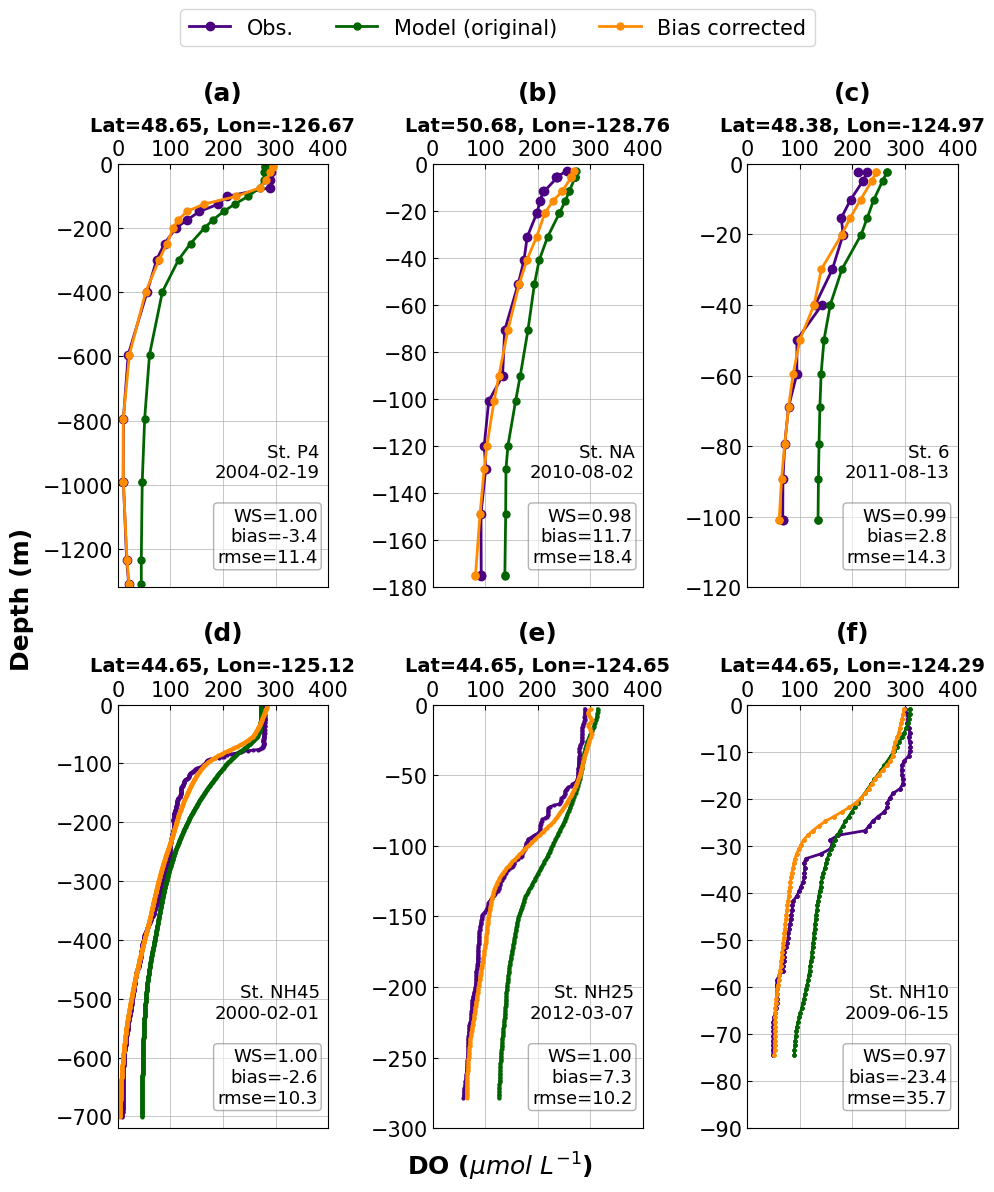

In [47]:
"""
plot target cid together for manuscript (Fig. 6)
"""
selected_cids = [
                843, # P4,
                1681,
                1839,
                4220, #NH45
                7774, # NH25
                5701 # NH10 or 5176
                 ]

# selected_cids = [2523, 2182, 1551, 1632]
# selected_cids = [2523, 1551, 8,  1632, ]
# corresponding panel labels
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

# subset grouped list
grouped_dict = dict(grouped)

selected_grouped = [
    (cid, grouped_dict[cid])
    for cid in selected_cids
]

# make 2x2 figure
fig, axes = plt.subplots(2, 3, figsize=(10, 12),facecolor='white')
axes = axes.flatten()

for ax, (label, (cid, group)) in zip(axes, zip(panel_labels, selected_grouped)):

    group = group.sort_values('z')
    if len(group['z']) > 35:
        ms_obs = 4
        ms_model = 4
    else:
        ms_obs = 12
        ms_model = 10

    ax.plot(group['DO_obs'], group['z'],
            marker='.', linestyle='-',
            linewidth=2,
            color='indigo',
            label='Obs.',
            markersize=ms_obs)

    ax.plot(group['DO (uM)'], group['z'],
            marker='.', linestyle='-',
            linewidth=2,
            color='darkgreen',
            label='Model (original)',
            markersize=ms_model)

    ax.plot(group['bias_corrected_DO'], group['z'],
            marker='.', linestyle='-',
            linewidth=2,
            color='darkorange',
            label='Bias corrected',
            markersize=ms_model)

    # metrics
    obs = group['DO_obs'].values
    mod = group['bias_corrected_DO'].values

    valid = np.isfinite(obs) & np.isfinite(mod)
    obs = obs[valid]
    mod = mod[valid]

    bias = np.nanmean(mod - obs)

    rmse = np.sqrt(np.nanmean((mod - obs)**2))

    obs_mean = np.nanmean(obs)

    denom = np.nansum(
        (np.abs(mod - obs_mean) +
         np.abs(obs - obs_mean))**2
    )

    ws = np.nan if denom == 0 else \
         1 - np.nansum((mod - obs)**2) / denom

    lat = group['lat'].iloc[0]
    lon = group['lon'].iloc[0]
    date = pd.to_datetime(group['time'].iloc[0]).strftime('%Y-%m-%d')
    name = group['name'].iloc[0]
    if pd.isna(name) or name == 'None':
        name = 'NA'
    # annotation box
    ax.text(
        0.95, 0.05,
        f'WS={ws:.2f}\nbias={bias:.1f}\nrmse={rmse:.1f}',
        transform=ax.transAxes,
        ha='right',
        va='bottom',
        fontsize=13,
        bbox=dict(
            boxstyle='round,pad=0.2',
            fc='white',
            ec='gray',
            alpha=0.6
        )
    )

    # replace cid title with panel label
    ax.set_title(
        f'\nLat={lat:.2f}, Lon={lon:.2f}',
        fontsize=14,
        fontweight='bold'
    )

    ax.text(
    0.5, 1.14,
    label,
    transform=ax.transAxes,
    ha='center',
    va='bottom',
    fontsize=18,
    fontweight='bold'
)


    zmin = np.floor(group['z'].min() / 30) * 30
    ax.set_ylim(zmin, 0)
    ax.set_xlim([0, 400])
    ax.set_xticks(np.arange(0, 400+1, 100))
    ax.xaxis.set_label_position('top')
    ax.xaxis.tick_top()
    ax.grid(which = 'major', linestyle = '-', linewidth = 0.5)

    ax.text(
        0.96, 0.25,
        f'St. {name}\n{date}',
        transform=ax.transAxes,
        ha='right',
        va='bottom',
        fontsize=13,

    )
# shared labels
fig.text(
    0.5, 0.02,
    'DO ($\\mu mol\\ L^{-1}$)',
    ha='center',
    fontsize=18,
    fontweight='bold'
)

fig.text(
    0.01, 0.5,
    'Depth (m)',
    va='center',
    rotation='vertical',
    fontsize=18,
    fontweight='bold'
)

# shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='upper center',
    ncol=3,
    fontsize=15
)

fig.tight_layout(rect=[0.02, 0.03, 1, 0.95])

plt.savefig(
    f'{fig_dir}/Fig.6_selected_profiles_3x2.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [49]:
# calculate the residuals

X_test['residuals'] = X_test['bias_corrected_DO'] - X_test['DO_obs']  # bias-corrected DO - obs DO
X_test['abs_residual'] = np.abs(X_test['residuals'])
shallow = X_test[X_test['z'] > -30]
deep = X_test[X_test['z'] <= -30]
# absolute residual
X_test['abs_residual'] = np.abs(X_test['residuals'])

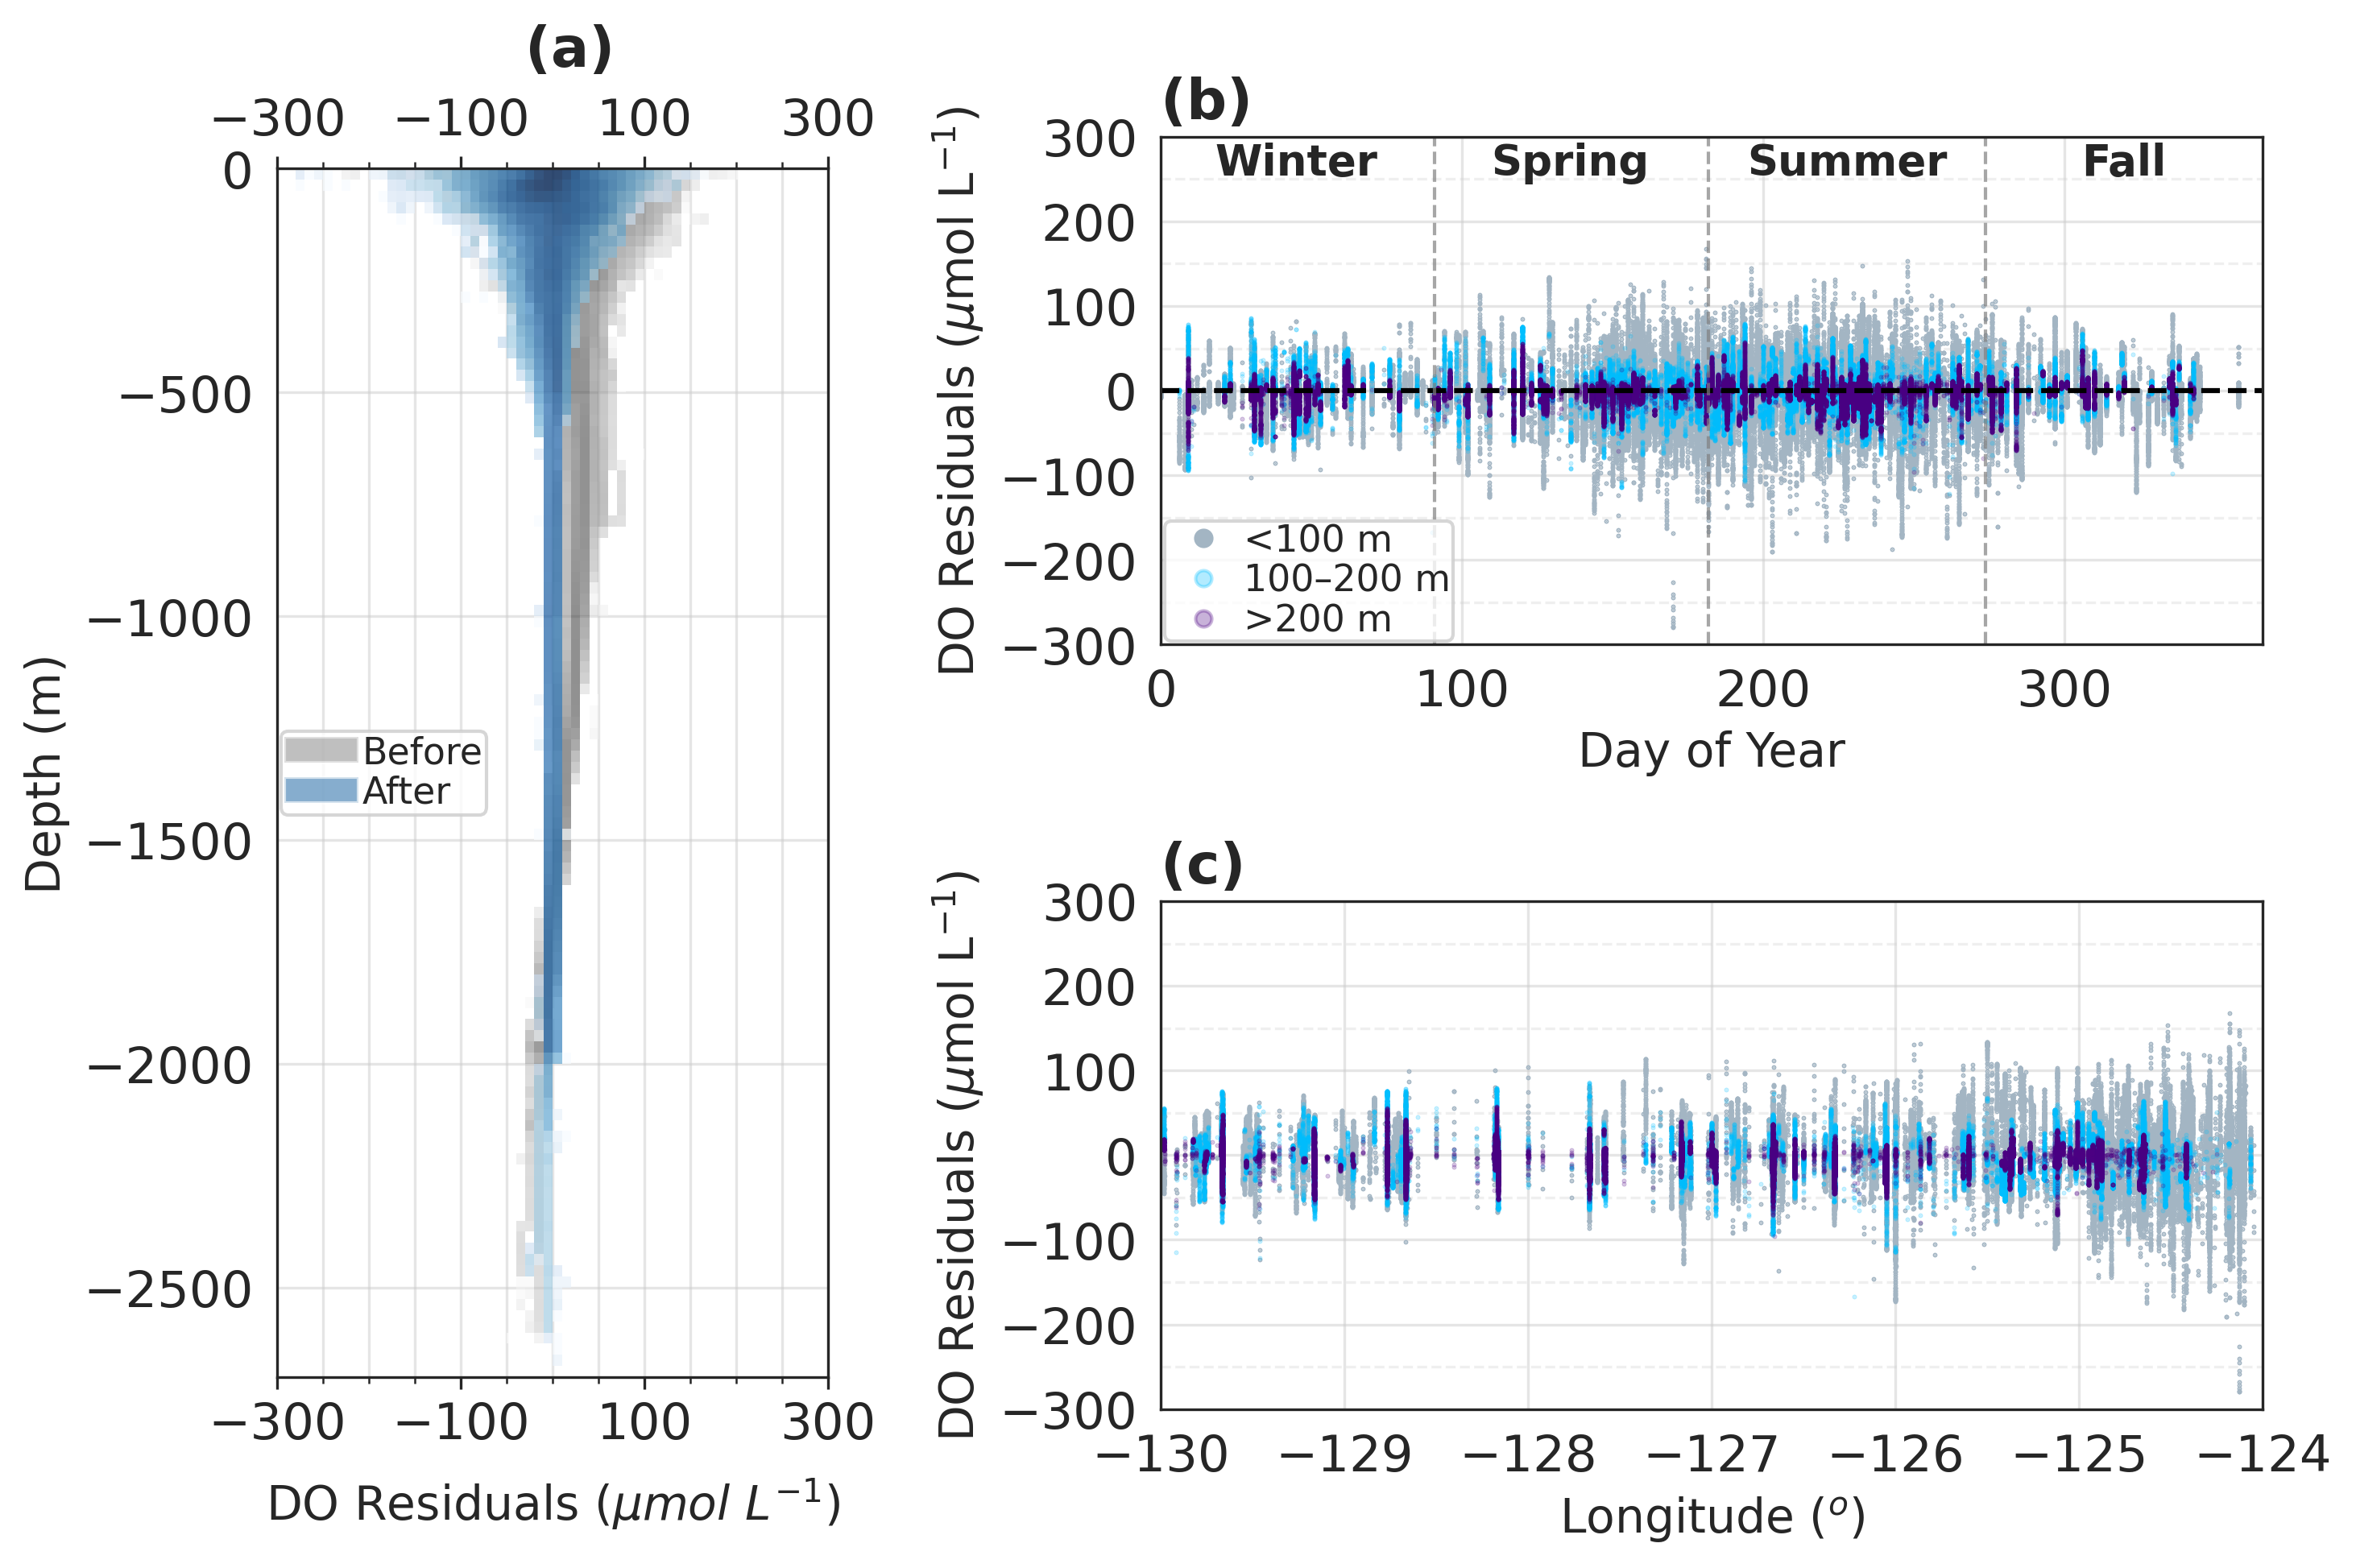

In [83]:
# plot the stats of the residuals

plt.close('all')
fs = 14
sns.set_style("white")
fig = plt.figure(figsize=(10, 7), dpi=300, constrained_layout=False)

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 2],
    # height_ratios=[0.3, 1, 1]
)
# -------------------------
# Left panel:  spans both rows
# -------------------------
ax1 = fig.add_subplot(gs[:, 0])


bins_x = np.arange(-300, 301, 10)
bins_z = np.arange(-3000, 1, 25)

# Before correction: gray
h1 = ax1.hist2d(
    y_test,
    X_test['z'],
    bins=[bins_x, bins_z],
    cmap='Greys',
    norm=LogNorm(),
    cmin=1,
    alpha=0.5
)

# After correction: orange
h2 = ax1.hist2d(
    X_test['residuals'],
    X_test['z'],
    bins=[bins_x, bins_z],
    cmap='Blues',
    norm=LogNorm(),
    cmin=1,
    alpha=0.65
)

handles = [
    Patch(facecolor='gray', alpha=0.5, label='Before'),
    Patch(facecolor='steelblue', alpha=0.65, label='After')
]

ax1.legend(
    handles=handles,
    fontsize=11,
    markerscale=2,
    loc='center left',
    borderpad=0.1,      # padding between frame and contents
    labelspacing=0.1,   # vertical spacing between entries
    handletextpad=0.1,  # space between marker and text
    borderaxespad=0.1,   # space between legend and axes edge
         )

# axis settings
ax1.set_ylim(-2700,0)
ax1.set_xlim(-300, 300)
ax1.set_xticks(np.arange(-300, 301, 200))
ax1.set_xticks(np.arange(-300,301, 50), minor=True)


ax1.xaxis.set_label_position('bottom')
ax1.xaxis.set_ticks_position('both')
ax1.tick_params(axis='x', top=True, bottom=True,     labeltop=True,    labelbottom=True)
ax1.set_xlabel(
    'DO Residuals ($\mu mol\ L^{-1}$)',
    fontsize=fs,
    # fontweight='bold',
    labelpad=8
)
ax1.set_ylabel(
    'Depth (m)',
    fontsize=14,
)
# ax1.grid(False)
ax1.grid(which='both', linestyle='-', alpha=0.5)
ax1.set_facecolor('white')
ax1.text(
    0.45, 1.12,
    '(a)',
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax1.transAxes,
    va='top',
    fontsize=fs*1.2,
    fontweight='bold',
)


# Right column
ax2 = fig.add_subplot(gs[0, 1])

bias = X_test['residuals'].values
z = X_test['z'].values
# convert back to dayofyear
theta = np.arctan2(X_test['sin_t'], X_test['cos_t'])  # [-π, π]
# Convert to [0, 2π)
theta = np.mod(theta, 2 * np.pi)
# Convert angle back to day of year
time = theta * 365 / (2 * np.pi)
# time = pd.to_datetime(X_test['time']).dt.dayofyear.values
#
alpha = 0.3
ms = 0.8
colors = ['#A3B5C3','deepskyblue','indigo', 'darkorange','#FC6C85']

mask = z > -100
ax2.plot(
    time[mask], bias[mask],
    '.', color=colors[0],
    # alpha=0.5,
    markersize=ms,
    label='<100 m'
)

mask = (z <= -100) & (z >= -200)
ax2.plot(
    time[mask], bias[mask],
    '.', color=colors[1],
    alpha=alpha,
    markersize=ms,
    label='100–200 m'
)

mask = z < -200
ax2.plot(
    time[mask], bias[mask],
    '.', color=colors[2],
    alpha=alpha,
    markersize=ms,
    label='>200 m'
)

ax2.axhline(0, color='k', linestyle='--', linewidth=1.5)
# ax.text(-13, -10, '0',   ha='center', fontsize=12)
ax2.set_xlim([0, 366])
ax2.set_ylim([-300, 300])
# y-axis major ticks every 100
ax2.set_yticks(np.arange(-300, 301, 100))
# y-axis minor ticks every 50
ax2.set_yticks(np.arange(-300, 301, 50), minor=True)
# grids
ax2.grid(which='major', linestyle='-', alpha=0.5)
ax2.grid(which='minor', linestyle='--', alpha=0.3)
# approximate season boundaries (DOY)
season_lines = [91, 182, 274]

for d in season_lines:
    ax2.axvline(
        d,
        color='gray',
        linestyle='--',
        linewidth=1,
        alpha=0.7
    )
ypos = ax2.get_ylim()[1] * 0.85
ax2.text(45,  ypos, 'Winter', ha='center', fontsize=fs/1.1, fontweight='bold')
ax2.text(136, ypos, 'Spring', ha='center', fontsize=fs/1.1, fontweight='bold')
ax2.text(228, ypos, 'Summer', ha='center', fontsize=fs/1.1, fontweight='bold')
ax2.text(320, ypos, 'Fall',   ha='center', fontsize=fs/1.1, fontweight='bold')

ax2.set_xlabel('Day of Year',fontsize=fs)
ax2.set_ylabel('DO Residuals ($\mu$mol L$^{{-1}}$)',fontsize=fs)


ax2.legend(markerscale=12,
          loc='lower left',
          fontsize=11,
        borderpad=0.05,      # padding between frame and contents
        labelspacing=0.1,   # vertical spacing between entries
        handletextpad=0.1,  # space between marker and text
        borderaxespad=0.1,   # space between legend and axes edge
       )

ax2.text(
    0, 1.12,
    '(b)',
    transform=ax2.transAxes,
    va='top',
    fontsize=fs*1.2,
    fontweight='bold',
)


ax3 = fig.add_subplot(gs[1, 1])

lat = X_test['lat'].values
lon = X_test['lon'].values


mask = z > -100
ax3.plot(
    lon[mask], bias[mask],
    '.', color=colors[0],
    # alpha=0.5,
    markersize=ms,
    label='<100 m'
)

mask = (z <= -100) & (z >= -200)
ax3.plot(
    lon[mask], bias[mask],
    '.', color=colors[1],
    alpha=alpha,
    markersize=ms,
    label='100–200 m'
)

mask = z < -200
ax3.plot(
    lon[mask], bias[mask],
    '.', color=colors[2],
    alpha=alpha,
    markersize=ms,
    label='>200 m'
)
ax3.set_xlim([-130, -124])
ax3.set_ylim([-300, 300])
ax3.set_yticks(np.arange(-300, 301, 100))
ax3.set_yticks(np.arange(-300,301, 50), minor=True)
# grids
ax3.grid(which='major', linestyle='-', alpha=0.5)
ax3.grid(which='minor', linestyle='--', alpha=0.3)
ax3.text(
    0, 1.12,
    '(c)',
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax3.transAxes,
    va='top',
    fontsize=fs*1.2,
    fontweight='bold',
)
ax3.set_ylabel('DO Residuals ($\mu$mol L$^{{-1}}$)',fontsize=fs)
ax3.set_xlabel('Longitude ($^{o}$)',fontsize=fs)

plt.tight_layout(rect=[0, 0, 1, 1])
# Get current position
pos = ax1.get_position()

# Shrink only the height (e.g., to 75% of original)
new_height = pos.height * 0.95

# Keep it vertically centered
new_y0 = pos.y0 + (pos.height - new_height) / 2

ax1.set_position([pos.x0, new_y0, pos.width, new_height])

plt.savefig(f'{fig_dir}/DO_residuals_distribution_1x3.png', dpi=300)
plt.show()

In [15]:
# plot all of the casts
plotting = False
if plotting:
    panel_labels = ['(a)', '(b)', '(c)', '(d)']
    DO_lim = [0, 400]
    # loop through all cids, 4 casts per figure
    for start_idx in range(0, len(grouped), 4):

        selected_grouped = grouped[start_idx:start_idx + 4]

        # make 2x2 figure
        fig, axes = plt.subplots(
            2, 2,
            figsize=(9, 12),
            facecolor='white'
        )

        axes = axes.flatten()

        # turn off all axes first
        # useful if the last figure has fewer than 4 casts
        for ax in axes:
            ax.set_visible(False)

        for ax, label, (cid, group) in zip(
            axes,
            panel_labels,
            selected_grouped
        ):

            ax.set_visible(True)

            group = group.sort_values('z')

            # observation
            ax.plot(
                group['DO_obs'],
                group['z'],
                marker='.',
                linestyle='-',
                linewidth=2,
                color='indigo',
                label='Obs.',
                markersize=12
            )

            # original model
            ax.plot(
                group['DO (uM)'],
                group['z'],
                marker='.',
                linestyle='-',
                linewidth=2,
                color='darkgreen',
                label='Model (original)',
                markersize=10
            )

            # bias corrected
            ax.plot(
                group['bias_corrected_DO'],
                group['z'],
                marker='.',
                linestyle='-',
                linewidth=2,
                color='darkorange',
                label='Bias corrected',
                markersize=10
            )

            # -------------------------
            # metrics
            # -------------------------
            obs = group['DO_obs'].values
            mod = group['bias_corrected_DO'].values

            valid = np.isfinite(obs) & np.isfinite(mod)

            obs = obs[valid]
            mod = mod[valid]

            bias = np.nanmean(mod - obs)

            rmse = np.sqrt(
                np.nanmean((mod - obs)**2)
            )

            obs_mean = np.nanmean(obs)

            denom = np.nansum(
                (
                    np.abs(mod - obs_mean)
                    + np.abs(obs - obs_mean)
                )**2
            )

            ws = (
                np.nan
                if denom == 0
                else 1 - np.nansum((mod - obs)**2) / denom
            )

            # location
            lat = group['lat'].iloc[0]
            lon = group['lon'].iloc[0]

            # -------------------------
            # annotation box
            # -------------------------
            ax.text(
                0.95,
                0.05,
                f'WS={ws:.2f}\n'
                f'bias={bias:.1f}\n'
                f'rmse={rmse:.1f}',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                fontsize=13,
                bbox=dict(
                    boxstyle='round,pad=0.2',
                    fc='white',
                    ec='gray',
                    alpha=0.6
                )
            )

            # -------------------------
            # title
            # -------------------------
            ax.set_title(
                f'cid={cid}\n'
                f'Lat={lat:.2f}, Lon={lon:.2f}',
                fontsize=14,
                fontweight='bold'
            )

            # panel label
            ax.text(
                0.5,
                1.19,
                label,
                transform=ax.transAxes,
                ha='center',
                va='bottom',
                fontsize=18,
                fontweight='bold'
            )

            # axes
            ax.set_xlim(DO_lim)

            zmin = np.floor(group['z'].min() / 50) * 50

            ax.set_ylim(zmin, 0)

            ax.xaxis.set_label_position('top')
            ax.xaxis.tick_top()

        # -------------------------
        # shared labels
        # -------------------------
        fig.text(
            0.5,
            0.02,
            'DO ($\\mu mol\\ L^{-1}$)',
            ha='center',
            fontsize=18,
            fontweight='bold'
        )

        fig.text(
            0.01,
            0.5,
            'Depth (m)',
            va='center',
            rotation='vertical',
            fontsize=18,
            fontweight='bold'
        )

        # -------------------------
        # shared legend
        # -------------------------
        visible_axes = [ax for ax in axes if ax.get_visible()]

        handles, legend_labels = (
            visible_axes[0].get_legend_handles_labels()
        )

        fig.legend(
            handles,
            legend_labels,
            loc='upper center',
            ncol=3,
            fontsize=15
        )

        fig.tight_layout(
            rect=[0.02, 0.05, 1, 0.93]
        )

        # identify cids included in this figure
        cid_list = [cid for cid, group in selected_grouped]

        # save
        plt.savefig(
            f'{fig_dir}/profiles_'
            f'{cid_list[0]}-{cid_list[-1]}.png',
            dpi=300,
            bbox_inches='tight'
        )

        # plt.show()

        # important when making many figures
        plt.close(fig)
